<h1>Face Detetion with Convolutional Neural Network</h1>

<h2>Introduction</h2>

<h3>Dataset</h3>

<h2>Environment Set-Up</h2>

In [1]:
#pip install ultralytics

In [2]:
import os
import sys
# Setting Hadoop home directory for the JVM
os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-21.0.12"
os.environ["SPARK_HOME"] = r"C:\tools\Anaconda3\Lib\site-packages\pyspark"
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = (
    os.path.join(os.environ["JAVA_HOME"], "bin") + os.pathsep +
    os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep + 
    os.environ["PATH"]
    )

# TenserFlow / oneDNN CPU tuning
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["OMP_NUM_THREADS"] = "8"
os.environ["KMP_BLOCKTIME"] = "1"
os.environ["KMP_AFFINITY"] = "granularity=fine,compact,1,0"

In [73]:
from PIL import Image
import glob
import shutil
import hashlib
import random
import regex
from ultralytics import YOLO
#-------------------------------------------------------------------------------
# Data Manipulation Libraries
#-------------------------------------------------------------------------------
#Pandas : Used for data loading, manipulation, cleaning, and tabular data structures 
import pandas as pd
#-------------------------------------------------------------------------------
# Data Visualization Libraries
#-------------------------------------------------------------------------------
import seaborn as sns
import matplotlib.pyplot as plt
#-------------------------------------------------------------------------------
# Mathematical and Statistical Computing Libraries
#-------------------------------------------------------------------------------
import numpy as np
from scipy.stats import pearsonr


#-------------------------------------------------------------------------------
# Machine Learning Models for Sentiment Classification.
#-------------------------------------------------------------------------------
#-------------------------------------------------------------------------------
# Model Evaluation Metrics Libraries
#-------------------------------------------------------------------------------
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
import json
import os
#-------------------------------------------------------------------------------
# Model Selection and ValidationLibraries
#-------------------------------------------------------------------------------
# GridSearchCV: Hyperparameter tuning using cross-validation
# StratifiedKFold: Preserves class distribution across folds
#-------------------------------------------------------------------------------
# Notebook Visualization Settings
#-------------------------------------------------------------------------------
# Enables inline plotting in Jupyter notebooks.
%matplotlib inline

# Sets Seaborn dark theme for cleaner plots.
sns.set_style("darkgrid")
# Sets default color palette
sns.set_palette('husl',8)

##For users to install: wordclou and gensim optuna

In [4]:
import findspark
findspark.init()
import pyspark
from pyspark.sql import functions as F
from pyspark.sql.types import IntegerType, StructField, StructType, StringType, DoubleType
from pyspark.sql import SparkSession

spark =( SparkSession.builder
        .master("local[*]")
        .config('spark.hadoop.home.dir', r'C:\hadoop')
        .config('spark.jars.packages','org.postgresql:postgresql:42.7.12')
        .config('spark.driver.memory','8g')
        .config('spark.sql.shuffle.partitions','8')
        .appName("Facial Recognition")
        .getOrCreate()
)
print('Spark Version:', spark.version)
print('Hadoop Home:', os.environ["HADOOP_HOME"])

Spark Version: 4.2.0
Hadoop Home: C:\hadoop


In [5]:
BASE = r"C:\Users\lab_services_student\Desktop\FacialRecognitionWithCNN\datasets"
IMG_TRAIN = os.path.join(BASE, "images", "train")
IMG_VAL = os.path.join(BASE, "images", "val")
LBL_TRAIN = os.path.join(BASE, "labels", "train")
LBL_VAL = os.path.join(BASE, "labels", "val")
LBL2_DIR = os.path.join(BASE, "labels2")

<h2>Building PySpark DataFrame of the Annotations<h2>

In [6]:
# Parsing YOLO labels files into a Spark Dataframe
schema = StructType([
    StructField('filename',StringType(), False),
    StructField('split',StringType(), False),
    StructField('cls',IntegerType(), True),
    StructField('x_center',DoubleType(), True),
    StructField('y_center',DoubleType(), True),
    StructField('width',DoubleType(), True),
    StructField('height',DoubleType(), True),
])

def parse_label_file(file_path, split):
    fname = os.path.splitext(os.path.basename(file_path))[0]
    rows = []
    with open(file_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                rows.append((fname, split,
                             int(float(parts[0])),
                             float(parts[1]), float(parts[2]),
                             float(parts[3]), float(parts[4])))
            elif len(parts) == 0:
                #malformed line : records with null so its visible in the audit
                rows.append((fname, split, None, None, None, None, None))
    return rows

label_rows = []
for split, label_dir in [('train', LBL_TRAIN), ('val', LBL_VAL) ]:
    for p in glob.glob(os.path.join(label_dir, '*.txt')):
        label_rows.extend(parse_label_file(p, split))

labels_df = spark.createDataFrame(label_rows, schema=schema).cache()
print('Total annotated boxes: ', labels_df.count())
labels_df.show(5, truncate=False)

Total annotated boxes:  51846
+----------------+-----+---+------------+-------------------+-------------------+-------------------+
|filename        |split|cls|x_center    |y_center           |width              |height             |
+----------------+-----+---+------------+-------------------+-------------------+-------------------+
|00006c07d2b033d1|train|0  |0.3943359375|0.325390125        |0.139063           |0.192188           |
|00006c07d2b033d1|train|0  |0.6656245   |0.315625           |0.1421880000000001 |0.189062           |
|0000bee39176697a|train|0  |0.2209375   |0.4151388225584594 |0.078125           |0.14449399999999998|
|0000bee39176697a|train|0  |0.3569921875|0.32394094910591476|0.085625           |0.167401           |
|0000bee39176697a|train|0  |0.6877734375|0.2591553287482806 |0.12312500000000004|0.23259900000000003|
+----------------+-----+---+------------+-------------------+-------------------+-------------------+
only showing top 5 rows


<h2>Exploratory Data Analysis</h2>

<h3>Data Quality Assessment<h3>

In [7]:
# Completenes
# Will check orphaned images and orphaned label files
def list_images(folder, split):
    return [(os.path.splitext(os.path.basename(p))[0], split)
            for p in glob.glob(os.path.join(folder, '*.jpg'))]

img_rows = (list_images(IMG_TRAIN,'train') + list_images(IMG_VAL, 'val'))

img_schema = StructType([StructField('filename',StringType()), StructField('split',StringType())])

images_df = spark.createDataFrame(img_rows, schema=img_schema).cache()

label_names_df = (labels_df.select('filename','split').distinct())

orphaned_images = images_df.join(label_names_df, on = ['filename','split'], how='left_anti')

orphaned_labels = label_names_df.join(images_df, on = ['filename','split'], how='left_anti')

In [8]:
print('Images without labels:', orphaned_images.count())
print('Labels without images:', orphaned_labels.count())
orphaned_images.show(5, truncate=False)

Images without labels: 0
Labels without images: 0
+--------+-----+
|filename|split|
+--------+-----+
+--------+-----+



In [9]:
# Self consistency
#Comparing labels/YOLO vs labels2
def parse_pixel_label(path):
    #return list of (x_min, y_min, x_max, y_max) in pixels
    boxes = []
    if not os.path.exists(path):
        return boxes
    with open(path,'r') as f:
        for line in f:
            parts = line.strip().split()
            # Format: Human face x_min, y_min, x_max, y_max
            if len(parts) >= 6 and parts[0].lower() == 'human' and parts[1].lower() == 'face':
                boxes.append(tuple(float(v) for v in parts[2:6]))
    return boxes

consistency_report = []
all_label_names = [r[0] + '.txt' for r in label_names_df.select('filename').collect()]

#Selecting 1000 files to check for consistency
random.seed(42)
sample_names = random.sample(all_label_names, min(5000, len(all_label_names)))
for name in sample_names:
    stem = os.path.splitext(name)[0]
    #Locate image
    img_path = None
    for d in (IMG_TRAIN, IMG_VAL):
        cand = os.path.join(d, stem +'.jpg')
        if os.path.exists(cand):
            img_path = cand
            break
    if img_path is None:
        continue
    with Image.open(img_path) as im:
        iw, ih = im.size

    # YOLO boxes
    yolo_path = os.path.join(LBL_TRAIN if 'train' in img_path else LBL_VAL, name)
    
    yolo_boxes = []
    with open(yolo_path) as f:
        for line in f:
            p = line.strip().split()
            if len(p) == 5:
                _, xc, yc, w, h = map(float, p)
                yolo_boxes.append(((xc - w/2)*iw, (yc- h/2)*ih,
                                   (xc + w/2)*iw, (yc + h/2 )*ih))
                
    pix_boxes = parse_pixel_label(os.path.join(LBL2_DIR, name))
    if len(yolo_boxes) != len(pix_boxes) and len(pix_boxes) > 0:
        diffs = [max(abs(a-b) for a,b in zip(y,p)) for y,p in zip(yolo_boxes, pix_boxes)]
        consistency_report.append((stem, len(pix_boxes), float(np.mean(diffs)),float(np.max(diffs))))
    else:
        consistency_report.append((stem, len(pix_boxes), np.nan, np.nan))


In [10]:
cons_df = spark.createDataFrame(consistency_report, schema=StructType([
    StructField('filename',StringType()),
    StructField('n_boxes',IntegerType()),
    StructField('mean_px_diff',DoubleType()),
    StructField('max_px_diff',DoubleType())
]))
print('Consistency Summary (pixels): ')
cons_df.select(F.mean('mean_px_diff').alias('avg_mean_px_diff'),
               F.max('max_px_diff').alias('worst_max_diff')).show()

Consistency Summary (pixels): 
+----------------+--------------+
|avg_mean_px_diff|worst_max_diff|
+----------------+--------------+
|             NaN|           NaN|
+----------------+--------------+



In [11]:
# Box size and aspect ratio distribution
# For reportign I will need img dimensions, so I will build a small image-metadate table
def get_dims(row):
    for d in (IMG_TRAIN, IMG_VAL):
        p = os.path.join(d, row['filename'] + '.jpg')
        if os.path.exists(p):
            with Image.open(p) as im:
                return (row['filename'], row['split'], int(im.size[0]), int(im.size[1]))
    return (row['filename'], row['split'], None, None)

dims_rows = [get_dims(r.asDict()) for r in images_df.collect()]
dims_df = spark.createDataFrame(dims_rows, schema=StructType([
    StructField('filename',StringType()),
    StructField('split',StringType()),
    StructField('img_w',IntegerType()),
    StructField('img_h',IntegerType())
])).cache()

boxes_df = (labels_df
            .join(dims_df, on=['filename','split'], how='inner')
            .withColumn('box_w_px', F.col('width')* F.col('img_w'))
            .withColumn('box_h_px', F.col('height') * F.col('img_h'))
            .withColumn('box_area_px', F.col('box_w_px') * F.col('box_h_px'))
            .withColumn('aspect_ratio', F.col('box_w_px') / F.col('box_h_px'))
            )

boxes_df.select(
    F.count('*').alias('n_boxes'),
    F.round(F.mean('box_area_px'), 1).alias('mean_area_px'),
    F.round(F.expr('percentile_approx(box_area_px, 0.5)'),1).alias('median_area_px'),
    F.round(F.expr('percentile_approx(box_area_px, 0.05)'),1).alias('p05_area_px'),
    F.round(F.mean('aspect_ratio'),3).alias('mean_aspect'),
    F.min('box_area_px').alias('min_area_px'),
    F.max('box_area_px').alias('max_area_px')
).show()


+-------+------------+--------------+-----------+-----------+-------------------+------------------+
|n_boxes|mean_area_px|median_area_px|p05_area_px|mean_aspect|        min_area_px|       max_area_px|
+-------+------------+--------------+-----------+-----------+-------------------+------------------+
|  51846|     22196.5|        5429.0|      297.4|      0.802|0.40943615999995964|1051718.4000000001|
+-------+------------+--------------+-----------+-----------+-------------------+------------------+



In [12]:
# Count of tiny boxes (below 16x16 px)
tiny_boxes = boxes_df.filter(F.col('box_area_px') < 256).count()
print(f'Boxes smaller than 16x16: {tiny_boxes} ({tiny_boxes/boxes_df.count()*100:.2f}%)')

Boxes smaller than 16x16: 2108 (4.07%)


In [13]:
# Negatives: Images with zero boxes
labelled = labels_df.select('filename', 'split').distinct()
negatives = images_df.join(labelled, on=['filename','split'], how='left_anti')
print('Images with no faces (negatives): ', negatives.count())

Images with no faces (negatives):  0


In [15]:
# Near-duplicate detection
def ahash(path, hash_size=8):
    with Image.open(path) as im:
        im = im.convert('L').resize((hash_size, hash_size))
        pixels = np.array(im, dtype=np.float32)
        bits = (pixels > pixels.mean()).astype(int).flatten()
        binary = ''.join(map(str, bits))
        return format(int(binary,2), f'0{hash_size * hash_size // 4}x')

hash_rows = []
for split, folder in [('train', IMG_TRAIN), ('val',IMG_VAL)]:
    for p in glob.glob(os.path.join(folder, '*.jpg')):
        hash_rows.append((os.path.splitext(os.path.basename(p))[0], split, ahash(p)))

hash_df = spark.createDataFrame(hash_rows, schema=StructType([StructField('filename',StringType()),
                                                                          StructField('split',StringType()),
                                                                          StructField('ahash',StringType())])).cache()
dup_pairs = (hash_df.alias('a').join(
    hash_df.alias('b'),
    (F.col('a.ahash') == F.col('b.ahash')) & (F.col('a.filename') < F.col('b.filename')))
             .select(F.col('a.filename').alias('file_a'), F.col('b.filename').alias('file_b'))
             )


In [16]:
print('Exact-hash duplicates pairs:', dup_pairs.count())

Exact-hash duplicates pairs: 21


<h3>Data Visualisation</h3>

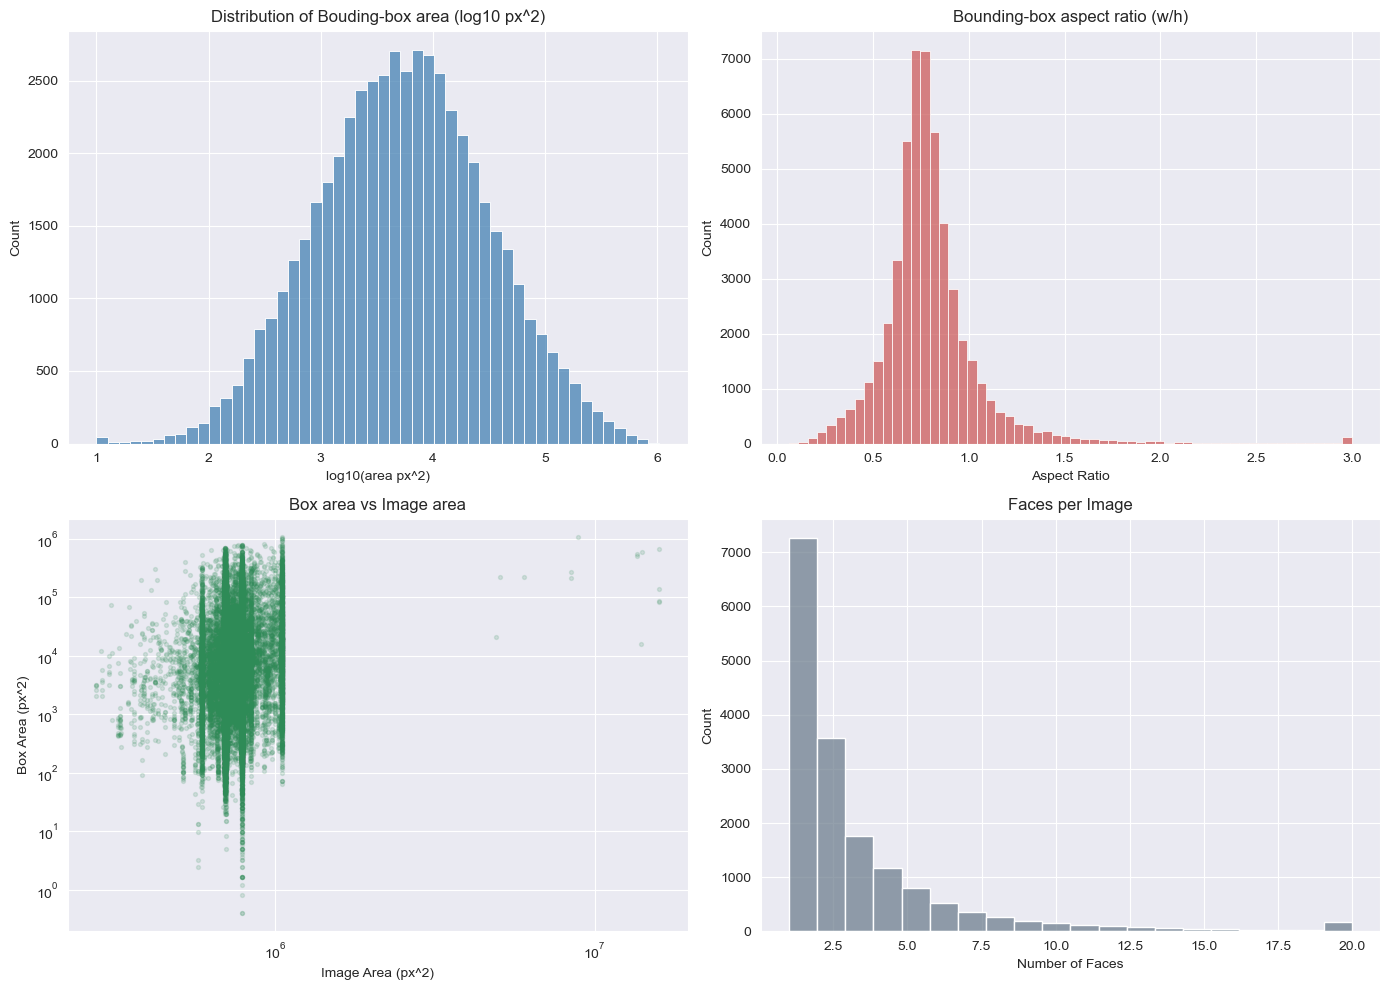

In [19]:
# Box area distribution
fig, axes = plt.subplots(2,2, figsize=(14,10))

# 1.1 Box Area distribution (log10)
pdf = boxes_df.select('box_area_px').toPandas()
pdf['log_area'] = np.log10(pdf['box_area_px']).clip(lower=1)
sns.histplot(pdf['log_area'], bins=50, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribution of Bouding-box area (log10 px^2)')
axes[0,0].set_xlabel('log10(area px^2)')

# 1.2 Aspect Ration
pdf_aspect = boxes_df.select('aspect_ratio').toPandas()
sns.histplot(pdf_aspect['aspect_ratio'].clip(0,3), bins=60, ax=axes[0,1], color='indianred')
axes[0,1].set_title('Bounding-box aspect ratio (w/h)')
axes[0,1].set_xlabel('Aspect Ratio')

# 2.1  Box area vs image area
# Checking if scale correlate with resolution
pdf_scale = boxes_df.select('img_w', 'img_h','box_area_px').toPandas()
pdf_scale['img_area'] = pdf_scale['img_w'] * pdf_scale['img_h']
axes[1,0].scatter(pdf_scale['img_area'], pdf_scale['box_area_px'], alpha=0.15, s=8, color='seagreen')
axes[1,0].set_xscale('log')
axes[1,0].set_yscale('log')
axes[1,0].set_title('Box area vs Image area')
axes[1,0].set_xlabel('Image Area (px^2)')
axes[1,0].set_ylabel('Box Area (px^2)')

# Boxes per Image
pdf_bpi = (labels_df.groupby('filename').count()
           .select('count').toPandas())
sns.histplot(pdf_bpi['count'].clip(0,20), bins=20, ax=axes[1,1], color='slategray')
axes[1,1].set_title('Faces per Image')
axes[1,1].set_xlabel('Number of Faces')

plt.tight_layout()
plt.show()

<h2>Feature Pre-processing</h2>

In [21]:
# Keeping only one image per duplicate
to_remove = (dup_pairs.select(F.col('file_b').alias('filename'))
             .distinct()
             .cache())
n_removed = to_remove.count()
print(f'Images to remove for exact-hash duplication: {n_removed}')

Images to remove for exact-hash duplication: 17


In [23]:
tiny_dropped_boxes = 0
images_emptied = 0
images_with_any_tiny = 0
MIN_BOX_AREA_PX = 256 # 16x16
SEED = 42
random.seed(SEED)


for split, lbl_dir, img_dir in [('img', LBL_TRAIN, IMG_TRAIN), ('val', LBL_VAL, IMG_VAL)]:
    for lbl_path in glob.glob(os.path.join(lbl_dir, '*.txt')):
        stem = os.path.splitext(os.path.basename(lbl_path))[0]
        img_path = os.path.join(img_dir, stem + '.jpg')
        if not os.path.exists(img_path):
            continue
        with Image.open(img_path) as im:
            iw, ih = im.size
        kept_lines = []
        dropped_here = 0
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                _, xc, yc, w, h = map(float, parts)
                area_px = (w*iw) * (h*ih)
                if area_px >= MIN_BOX_AREA_PX:
                    kept_lines.append(line)
                else:
                    dropped_here += 1

        tiny_dropped_boxes += dropped_here
        if dropped_here > 0 and len(kept_lines) > 0:
            images_with_any_tiny += 1
            
        if len(kept_lines) == 0 and dropped_here > 0:
            images_emptied += 1
            os.remove(lbl_path)

        elif dropped_here > 0:
            with open(lbl_path,'w') as f:
                f.writelines(kept_lines)

print(f'Boxes removed < (16 x 16 px) : {tiny_dropped_boxes}')
print(f'Images where at least one box dropped: {images_with_any_tiny}')
print(f'Images with left zero valid boxes: {images_emptied}')

Boxes removed < (16 x 16 px) : 2108
Images where at least one box dropped: 541
Images with left zero valid boxes: 26


In [25]:
# Building the the set of filenames to keep
keep_df = images_df.join(to_remove, on='filename', how='left_anti')
has_label = (labels_df.filter(F.col('cls').isNotNull()).select('filename').distinct())
keep_df = keep_df.join(has_label, on='filename').distinct()

print(f'Images retained:', keep_df.count())

# Re-partition into 70/10/20 at image level
all_files = keep_df.toPandas().sample(frac=1, random_state=SEED).reset_index(drop=True)

n = len(all_files)
n_train = int(0.70 * n)
n_val = int(0.10 * n)

all_files['new_split'] = 'train'
all_files.loc[n_train: n_train + n_val -1, 'new_split'] = 'val'
all_files.loc[n_train + n_val:, 'new_split'] = 'test'
print(all_files['new_split'].value_counts())

Images retained: 16716
new_split
train    11701
test      3344
val       1671
Name: count, dtype: int64


In [51]:
# Creating the Ultralytics-compatible directory tree
YOLO_ROOT = os.path.join(BASE, 'yolo')
for sub in ('images/train', 'images/val','images/test','labels/train','labels/val','labels/test'):
    os.makedirs(os.path.join(YOLO_ROOT, sub), exist_ok=True)

def move_pair(stem, src_split, dst_split):
    # image
    src_img = os.path.join(IMG_TRAIN if src_split == 'train' else IMG_VAL, stem + '.jpg')
    dst_img = os.path.join(YOLO_ROOT, 'images', dst_split, stem + '.jpg')
    if os.path.exists(src_img):
        shutil.copy(src_img, dst_img)
    
    #label
    src_lbl = os.path.join(LBL_TRAIN if src_split == 'train' else LBL_VAL, stem + '.txt')
    dst_lbl = os.path.join(YOLO_ROOT, 'labels', dst_split, stem + '.txt')
    if os.path.exists(src_lbl):
        shutil.copy(src_lbl, dst_lbl)
    
for _, row in all_files.iterrows():
    move_pair(row['filename'], row['split'], row['new_split'])

In [52]:
# Converting UTF-16 files into UTF-8
YOLO_ROOT = os.path.join(BASE, 'yolo')
LABEL_DIRS= [
    os.path.join(BASE, 'labels','train'),
    os.path.join(BASE,'labels','val'),
    os.path.join(YOLO_ROOT, 'labels','train'),
    os.path.join(YOLO_ROOT,'labels','val'),
    os.path.join(BASE, 'labels','test'),        
]

def fix_encoding(path):
    with open(path, 'rb') as f:
        raw = f.read()

    try:
        raw.decode('utf-8')
        return False
    except UnicodeDecodeError:
        pass
    for enc in ('utf-16','utf-16-le','utf-16-be','latin-1'):
        try:
            text = raw.decode(enc)
            break
        except UnicodeDecodeError:
            continue
    else:
        return False

    with open(path, 'w', encoding='utf-8') as f:
        f.write(text)
    return True
    

fixed = 0
for lbl_dir in (LABEL_DIRS):
    if not os.path.isdir(lbl_dir):
        continue
    for p in glob.glob(os.path.join(lbl_dir,'*.txt')):
        if fix_encoding(p):
            fixed += 1

print(f'Converted {fixed} label files to UTF-8')

Converted 0 label files to UTF-8


In [53]:
corrupt = os.path.join(YOLO_ROOT, "labels", "train", "ffff54ccbcad1111.txt")

if os.path.exists(corrupt):
    with open(corrupt, "rb") as f:
        head = f.read(20)
    print("yolo copy  first 20 bytes:", head)
    try:
        with open(corrupt, "r", encoding="utf-8") as f:
            print("yolo copy  first line:", f.readline().rstrip())
    except UnicodeDecodeError as e:
        print("yolo copy  STILL undecodable:", e)

src = os.path.join(BASE, "labels", "train", "ffff54ccbcad1111.txt")
if os.path.exists(src):
    with open(src, "rb") as f:
        print("original  first 20 bytes:", f.read(20))
    try:
        with open(src, "r", encoding="utf-8") as f:
            print("original  first line:", f.readline().rstrip())
    except UnicodeDecodeError as e:
        print("original  undecodable:", e)

yolo copy  first 20 bytes: b'0 0.3994908125 0.242'
yolo copy  first line: 0 0.3994908125 0.2423470625 0.259804 0.23692800000000003
original  first 20 bytes: b'0 0.3994908125 0.242'
original  first line: 0 0.3994908125 0.2423470625 0.259804 0.23692800000000003


In [54]:
# Write data.yaml
yaml_content = f"""path: {YOLO_ROOT}
train: images/train
val: images/val
test: images/test
names:
    0: face
"""

with open(os.path.join(YOLO_ROOT, 'data.yaml'), 'w') as f:
    f.write(yaml_content)
print(yaml_content)

path: C:\Users\lab_services_student\Desktop\FacialRecognitionWithCNN\datasets\yolo
train: images/train
val: images/val
test: images/test
names:
    0: face



<h2>Model Training </h2>

In [57]:
model = YOLO('yolov8n.pt')
results = model.train(
    data=os.path.join(YOLO_ROOT, 'data.yaml'),
    epochs=10,
    imgsz=416,
    batch=32,
    patience=5,
    workers=0,
    close_mosaic=3,
    project='runs',
    name='face_dectector_baseline',
    seed=SEED
    )

Ultralytics 8.4.215  Python-3.13.9 torch-2.15.0+cpu CPU (Intel Xeon Platinum 8370C CPU @ 2.80GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\lab_services_student\Desktop\FacialRecognitionWithCNN\datasets\yolo\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale

In [63]:
# Capturing training log into a 'history' dictionary
results_csv = os.path.join('runs','face_detector_baseline','results.csv')
hist_df = pd.read_csv(r'runs\detect\runs\face_dectector_baseline-4\results.csv')
hist_df.columns = [c.strip() for c in hist_df.columns]

history = {
    'epoch': hist_df['epoch'].values,
    'loss': hist_df['train/box_loss'].values + hist_df['train/cls_loss'].values + hist_df['train/dfl_loss'].values,
    'val_loss': hist_df['val/box_loss'].values + hist_df['val/cls_loss'].values + hist_df['val/dfl_loss'].values,
    'precision': hist_df['metrics/precision(B)'].values,
    'recall': hist_df['metrics/recall(B)'].values, 
    'mAP50': hist_df['metrics/mAP50(B)'].values, 
    'mAP50_95': hist_df['metrics/mAP50-95(B)'].values,
}

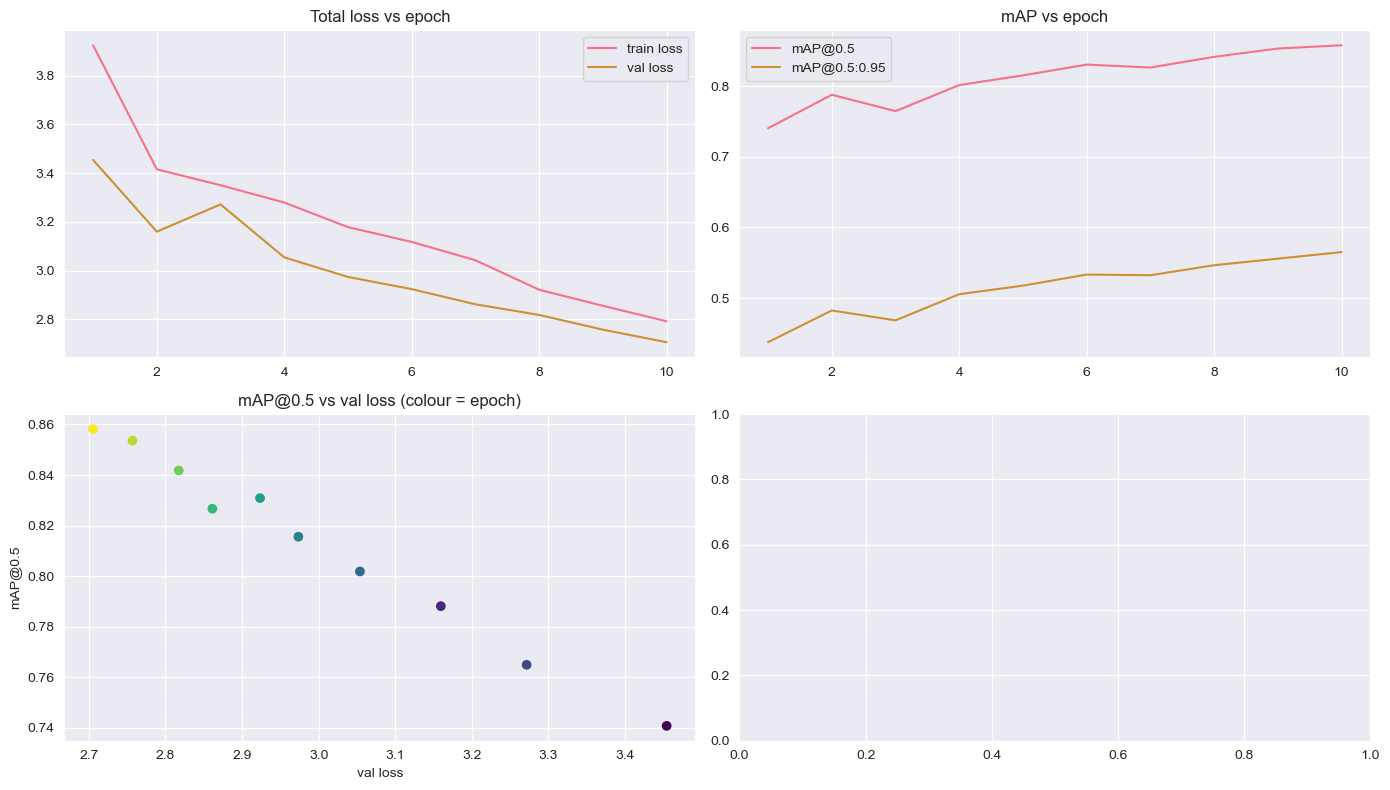

In [64]:
# Learning-curve plots
fig, axes = plt.subplots(2,2, figsize=(14,8))

axes[0, 0].plot(history['epoch'], history['loss'], label='train loss')
axes[0, 0].plot(history['epoch'], history['val_loss'], label='val loss')
axes[0, 0].set_title('Total loss vs epoch')
axes[0, 0].legend()

axes[0, 1].plot(history['epoch'], history['mAP50'], label='mAP@0.5')
axes[0, 1].plot(history['epoch'], history['mAP50_95'], label='mAP@0.5:0.95')
axes[0, 1].set_title('mAP vs epoch')
axes[0,1].legend()

axes[1, 0].scatter(history['val_loss'], history['mAP50'], c = history['epoch'], cmap='viridis')
axes[1, 0].set_xlabel('val loss')
axes[1, 0].set_ylabel('mAP@0.5')
axes[1, 0].set_title('mAP@0.5 vs val loss (colour = epoch)')

plt.tight_layout()
plt.show()

In [60]:
# Evaluation on test set
metrics = model.val(
    data=os.path.join(YOLO_ROOT, 'data.yaml'),
    split='test',
    imgsz=416,
    conf=0.25,
    iou=0.45,
)
print(f'mAP@0.5: {metrics.box.map50:.4f}')
print(f'mAP@0.5:0.95: {metrics.box.map:.4f}')
print(f'Precision : {metrics.box.mp:.4f}')
print(f'Recall : {metrics.box.mr:.4f}')

Ultralytics 8.4.215  Python-3.13.9 torch-2.15.0+cpu CPU (Intel Xeon Platinum 8370C CPU @ 2.80GHz)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 72.5±48.2 MB/s, size: 555.2 KB)
val: Scanning C:\Users\lab_services_student\Desktop\FacialRecognitionWithCNN\datasets\yolo\labels\test... 3339 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3344/3344 351.5it/s 9.5s0.0s
val: New cache created: C:\Users\lab_services_student\Desktop\FacialRecognitionWithCNN\datasets\yolo\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 209/209 1.8it/s 1:540.5sss
                   all       3344       9767       0.91      0.795      0.803      0.541
Speed: 0.5ms preprocess, 20.6ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to C:\Users\lab_services_student\Desktop\FacialRecognitionWithCNN\runs\detect\val-2
mAP@0.5: 0.8033
mAP@0.5:0

In [66]:
# Inference Speed
speed = metrics.speed
fps = 1000.0 / speed['inference']
print(f'Inference FPS :  {fps:.1f}')

Inference FPS :  48.6


<h2>Model Optimisation</h2>

In [68]:
# Setiting up the Configuration for optuna
CONFIG = {
    'n_trials' :25,
    'tune_epochs': 15,
    'timeout_sec': 22 * 3600,
    'tune_patience': 4,
    'pruner_n_startup': 5,
    'pruner_n_warmup': 5,
    'n_jobs': 1,
    'seed': SEED,
    'study_name':'face_detector_optuna',
    'storage':'sqlite:///optuna_face_detector.db',    
}

In [69]:
# Search Space
SEARCH_SPACE = {
    'lr0':{'kind':'float_log', 'bounds': (5e-4,2e-2)},
    'lrf': {'kind':'float', 'bounds': (0.005,0.20)},
    'momentum': {'kind':'float', 'bounds': (0.85, 0.98)},
    'weight_decay': {'kind':'float_log', 'bounds': (1e-5,5e-3)},
    'warmup_epochs':{'kind':'float', 'bounds': (1.0, 5.0)},
    'box': {'kind':'float', 'bounds': (5.0, 12.0)},
    'cls': {'kind':'float', 'bounds': (0.3, 2.0)},
    'mosaic': {'kind':'float', 'bounds': (0.5,1.0)},
    'mixup':{'kind':'float', 'bounds': (0.0, 0.3)},
    'hsv_h': {'kind':'float', 'bounds': (0.0, 0.5)},
    'hsv_s': {'kind':'float', 'bounds': (0.3, 0.9)},
    'hsv_v': {'kind':'float', 'bounds': (0.2,0.6)},
    'fliplr': {'kind':'float', 'bounds': (0.3,0.7)},
    'imgsz': {'kind':'categorical', 'choices':[416, 512]},
    'batch': {'kind':'categorical', 'choices':[16,32]},

}

def suggest_params(trial):
    params = {}
    for name, spec in SEARCH_SPACE.items():
        if spec['kind'] == 'float':
            lo, hi = spec['bounds']
            params[name] = trial.suggest_float(name, lo, hi)

        elif spec['kind'] == 'float_log':
            lo, hi = spec['bounds']
            params[name] = trial.suggest_float(name, lo, hi,log=True)
        
        elif spec['kind'] == 'categorical':
            params[name] = trial.suggest_categorical(name, spec['choices'])
        else:
            raise ValueError(f'Unknown kind {spec['kind']} for {name}')

In [70]:
# Setting up Prunning CALLBACk
def make_pruning_callback(trial):
    def callback(trainer):
        metric = trainer.metrics.get('metrics/mAP50-95(B)')
        if metric is None:
            metric = 0.0
        trial.report(metric, trainer.epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return callback

In [71]:
# Objective
def objective (trial):
    params = suggest_params(trial)
    imgsz = params.pop('imgsz')
    batch = params.pop('batch')

    model = YOLO('yolov8n.pt')
    model.add_callback('on_fit_epoch_end', make_pruning_callback(trial))

    model.train(
        data=os.path.join(YOLO_ROOT, 'data.yaml'),
        epochs=CONFIG['tune_epochs'],
        patience=CONFIG['tune_patience'],
        imgsz=imgsz,
        batch=batch,
        optimizer='SGD',
        project='runs_optuna',
        name=f'trial_{trial.number:03d}',
        fraction=0.2,
        exist_ok=True,
        verbose=False,
        seed=CONFIG['seed'],
        **params,
    )
    csv_path = os.path.join('runs_optuna', f'trial_{trial.number:03d}', 'results.csv')
    best = 0.0
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        df.columns = [c.strip() for c in df.columns]
        col = 'metrics/mAP0-95(B)'
        if col in df.columns:
            best = float(df[col].max())
            
    return best

In [72]:
# Study and Optimise
study = optuna.create_study(
    study_name = CONFIG['study_name'],
    storage=CONFIG['storage'],
    direction='maximize',
    sampler = TPESampler(seed=CONFIG['seed']),
    pruner = MedianPruner(n_startup_trials=CONFIG['pruner_n_startup'], n_warmup_steps= CONFIG['pruner_n_warmup']),
    load_if_exists=True
)

NameError: name 'optuna' is not defined

In [ ]:
# Results
print('\n--- Optuna Study Summary ---')
print(f'Trials total : {len(study.trials)}')
print(f"Trials pruner: {sum(1 for t in study.trials if t.state.name == 'PRUNED')}")
print(f'Best trial: #{study.best_trial.number}')
print(f'Best mAP@0.5:0.95: {study.best_value:.4f}')
print('Best Hyperparameters')
for k, v in study.best_params.items():
    print(f'{k:>16} = {v}')

In [ ]:
with open("best_params.json", 'w') as f:
    json.dump({
        'best_value': study.best_value,
        'best_trial': study.best_trial.number,
        'params': study.best_params
    }, f, ident=2)
print('\nSaved to best_params.json')

In [ ]:
# Retraining Model with best configuration
best = study.best_params.copy()
best_imgsz = best.pop('imgsz')
best_batch = best.pop('batch')

FINAL_EPOCHS = None
FINAL_PATIENCE = None

final_model = YOLO('yolov8n.pt')
final_results = final_model.train(
    data=os.path.join(YOLO_ROOT, 'data.yaml'),
    epochs=FINAL_EPOCHS,
    patience=FINAL_PATIENCE,
    imgsz=best_imgsz,
    batch=best_batch,
    optimizer='SGD',
    project='runs',
    name='face_detector_optimised',
    seed=CONFIG['need'],
    **best,
)

<h2>Final Model Evaluation</h2>

In [ ]:
# Capturing training log into a 'history' dictionary
final_results_csv = os.path.join('runs','face_detector_baseline','results.csv')
final_hist_df = pd.read_csv(r'runs\detect\runs\face_dectector_baseline\results.csv')
final_hist_df.columns = [c.strip() for c in hist_df.columns]

final_history = {
    'epoch': final_hist_df['epoch'].values,
    'loss': final_hist_df['train/box_loss'].values + final_hist_df['train/cls_loss'].values + final_hist_df['train/dfl_loss'].values,
    'val_loss': final_hist_df['val/box_loss'].values + final_hist_df['val/cls_loss'].values + final_hist_df['val/dfl_loss'].values,
    'precision': final_hist_df['metrics/precision(B)'].values,
    'recall': final_hist_df['metrics/recall(B)'].values, 
    'mAP50': final_hist_df['metrics/mAP50(B)'].values, 
    'mAP50_95': final_hist_df['metrics/mAP50-95(B)'].values,
}

In [ ]:
# Learning-curve plots
fig, axes = plt.subplots(2,2, figsize=(14,8))

axes[0, 0].plot(final_history['epoch'], final_history['loss'], label='train loss')
axes[0, 0].plot(final_history['epoch'], final_history['val_loss'], label='val loss')
axes[0, 0].set_title('Total loss vs epoch')
axes[0, 0].legend()

axes[0, 1].plot(final_history['epoch'], final_history['mAP50'], label='mAP@0.5')
axes[0, 1].plot(final_history['epoch'], final_history['mAP50_95'], label='mAP@0.5:0.95')
axes[0, 1].set_title('mAP vs epoch')
axes[0,1].legend()

axes[1, 0].scatter(final_history['val_loss'], final_history['mAP50'], c = final_history['epoch'], cmap='viridis')
axes[1, 0].set_xlabel('val loss')
axes[1, 0].set_ylabel('mAP@0.5')
axes[1, 0].set_title('mAP@0.5 vs val loss (colour = epoch)')

plt.tight_layout()
plt.show()

In [ ]:
# Evaluation on test set
final_metrics = final_model.val(
    data=os.path.join(YOLO_ROOT, 'data.yaml'),
    split='test',
    imgsz=416,
    conf=0.25,
    iou=0.45,
)
print(f'mAP@0.5: {metrics.box.map50:.4f}')
print(f'mAP@0.5:0.95: {metrics.box.map:.4f}')
print(f'Precision : {metrics.box.mp:.4f}')
print(f'Recall : {metrics.box.mr:.4f}')

In [ ]:
# Inference Speed
final_speed = final_metrics.speed
final_fps = 1000.0 / final_speed['inference']
print(f'Inference FPS :  {fps:.1f}')

<h2>Conclusion</h2>